# Cameron's PPH/CIG grids on 80-km equal-area cells (CSV output)

This notebook verifies Cameron's daily "practically perfect" probability + CIG grids for 2025 **as if they were forecasts**. It uses the same tile/cell method and output columns as `do_verf_outlooks_tiles.ipynb` (SPC outlooks) and `do_verf_pph_tiles.ipynb` (Chris's PPH), so the three can be compared.

**How Cameron's files differ from Chris's and SPC's:**
- One JSON per day (`YYYYMMDD.json`) holding plain **grids**, not polygons: 81 × 167 nodes every 40/111.1 = 0.36° from 125°W and 23°N (from his plotting code).
- Three versions per hazard:
    - `perfect`: raw PPH, with CIG from percentiles;
    - `spccal`: PPH and CIG calibrated to SPC's issuance frequency for each contour;
    - `target`: in between.
- Probabilities are **continuous** (percent), not SPC contour levels. CIG is also continuous (e.g. 1.02, 2.2). His plots shade CIG1 at ≥ 1, CIG2 at ≥ 2 and CIG3 at ≥ 3, so the **integer part** is used as the CIG level here.

**How the grids enter the tile method:** each grid node becomes the 0.36° box centred on it, a polygon carrying the node's value. The boxes are cut along the 80-km cells **once** (section 4), because the grid never changes. Each day then only attaches the grid values to those pieces; no forecast geometry is rebuilt. The exact probabilities are kept for the Brier score and MSE. They are binned to SPC's levels only for the category tables.

**Things to keep in mind:**
- **The valid window is not stated in the files.** It is assumed to be 12Z–12Z (`WINDOW`), the convective day. The SPC outlooks compared with it are the Day-1 files valid over the same 12Z–12Z window (`day1otlk_YYYYMMDD_1200`, the 06Z issuance), so both are scored against exactly the same observations. Section 6 checks how well different windows match his areas.
- **These are hindcasts.** The `perfect` version is built from the reports, so it is an upper reference. `spccal` is calibrated to look like SPC's contours, which makes it the closest like-for-like comparison with the outlooks.
- **The report source may differ** from Storm Events. Differences show up here as forecast errors.

In [1]:
import os, re, time
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import json
import matplotlib.pyplot as plt

## 1. Settings

In [2]:
DATES    = pd.date_range('2025-01-01', '2025-12-31', freq='D')    # the dates in Cameron's file names
WINDOW   = (12, 36)            # hours after 00Z on the day: 12Z to 12Z next day (assumed for Cameron's grids)
METHODS  = ['perfect', 'spccal', 'target']                         # Cameron's three versions

CRS_EQ   = 'EPSG:5070'        # NAD83 / CONUS Albers: equal-area, meters
CELL_M   = 80_000.0           # cell size (m)
BUFFER_M = 40_000.0           # report footprint radius (m)
GRID     = 1.0                # snap overlay results to a 1-m grid

# Cameron's grid, from his plotting code: nodes every 40/111.1 degrees, starting at 125W, 23N
GRID_DLL = 40.0 / 111.1
LONS     = np.arange(-125, -65, GRID_DLL)          # 167 columns
LATS     = np.arange(23, 52, GRID_DLL)             # 81 rows

# hazard -> key in Cameron's field names, Storm Events type, thresholds, column labels,
#           and SPC's probability levels (used only to bin the continuous probabilities for tables)
HAZARDS = {
    'torn': dict(key='tor',  event_type='Tornado',           thresholds=[0, 1, 2, 3, 4],
                 labels=['ef0', 'ef1', 'ef2', 'ef3', 'ef4'], levels=[2, 5, 10, 15, 30, 45, 60]),
    'wind': dict(key='wind', event_type='Thunderstorm Wind', thresholds=[50, 56, 65, 74, 83],
                 labels=['50kt', '56kt', '65kt', '74kt', '83kt'], levels=[5, 15, 30, 45, 60, 75, 90]),
    'hail': dict(key='hail', event_type='Hail',              thresholds=[1.0, 1.5, 2.0, 3.5],
                 labels=['1p0in', '1p5in', '2p0in', '3p5in'], levels=[5, 15, 30, 45, 60, 75, 90]),
}

DATA     = os.path.expanduser('~/Downloads/PPH_geojsons')
USA_FILE = f'{DATA}/usa_outline.geojson'
REG_FILE = f'{DATA}/bukovsky_regions_groups.geojson'
CAM_DIR  = os.path.expanduser('~/datasets/cameron_pph/2025')
OUT_DIR  = os.path.expanduser('~/datasets/cameron_tiles_2025')
OTLK_OUT = os.path.expanduser('~/datasets/outlook_tiles_2025_1200') # SPC Day-1 outlooks valid 12Z-12Z (the '1200' files), same dates
# Both years: the window for 31 Dec 2025 runs to 12Z on 1 Jan 2026
SE_DIR   = os.path.expanduser('~/datasets/storm_events')
STORM_EVENTS = [f'{SE_DIR}/StormEvents_details-ftp_v1.0_d2025_c20261119.csv.gz',
                f'{SE_DIR}/StormEvents_details-ftp_v1.0_d2026_c20261119.csv.gz']
os.makedirs(OUT_DIR, exist_ok=True)

def cam_path(day):
    return os.path.join(CAM_DIR, f'{day:%Y%m%d}.json')

def window(day):
    return day + pd.Timedelta(hours=WINDOW[0]), day + pd.Timedelta(hours=WINDOW[1])

## 2. Storm Events reports

The 2025 and 2026 files are read together, so the 31 Dec window has its overnight reports.

Storm Events times are local standard time, and `CZ_TIMEZONE` gives the offset: `CST-6` means UTC = local + 6 h. The offset is read from the string itself, so every zone is handled; your original cells dropped MST-7. Anything that can't be parsed is counted and reported.

The magnitude `mag` is the EF rating for tornadoes (EFU = 0), knots for wind, and inches for hail. Events below the lowest threshold, or with no magnitude, are left out and counted.

In [3]:
def tz_offset_hours(tz):
    # Hours to ADD to Storm Events local time to get UTC: 'CST-6' -> 6, 'AKST-9' -> 9, 'GST10' -> -10
    m = re.fullmatch(r'([A-Za-z]+)(-?)(\d+)', str(tz).strip())
    if m is None:
        return np.nan
    n = float(m.group(3))
    return n if m.group(2) == '-' else -n

EF = {'EFU': 0, 'EF0': 0, 'EF1': 1, 'EF2': 2, 'EF3': 3, 'EF4': 4, 'EF5': 5}

def storm_events_table(storm, haz):
    spec = HAZARDS[haz]
    d = storm[storm.EVENT_TYPE == spec['event_type']].copy()
    off_h = d.CZ_TIMEZONE.map(tz_offset_hours)
    off = pd.to_timedelta(off_h, unit='h')
    d['t0'] = pd.to_datetime(d.BEGIN_DATE_TIME, format='%d-%b-%y %H:%M:%S') + off
    d['t1'] = pd.to_datetime(d.END_DATE_TIME,   format='%d-%b-%y %H:%M:%S') + off
    d['lon0'], d['lat0'] = d.BEGIN_LON, d.BEGIN_LAT
    d['lon1'], d['lat1'] = d.END_LON.fillna(d.BEGIN_LON), d.END_LAT.fillna(d.BEGIN_LAT)
    d['mag'] = d.TOR_F_SCALE.map(EF) if haz == 'torn' else pd.to_numeric(d.MAGNITUDE, errors='coerce')
    bad_t = d.t1 < d.t0
    d.loc[bad_t, 't1'] = d.loc[bad_t, 't0']
    no_tz, no_loc = off_h.isna(), d.lat0.isna() | d.lon0.isna()
    below = ~(d.mag >= spec['thresholds'][0])            # also True when mag is missing
    print(f"{haz}: {len(d)} events | time zones {d.CZ_TIMEZONE.value_counts().to_dict()}")
    print(f"   dropped: {no_tz.sum()} unparseable time zone, {no_loc.sum()} no location, "
          f"{below.sum()} below {spec['thresholds'][0]} or no magnitude; {bad_t.sum()} had end before begin")
    keep = ~no_tz & ~no_loc & ~below
    return d.loc[keep, ['EVENT_ID', 'mag', 'MAGNITUDE_TYPE', 'TOR_F_SCALE',
                        't0', 't1', 'lon0', 'lat0', 'lon1', 'lat1']].reset_index(drop=True)

storm = pd.concat([pd.read_csv(f, low_memory=False) for f in STORM_EVENTS], ignore_index=True)
REPORTS = {haz: storm_events_table(storm, haz) for haz in HAZARDS}
for haz, r in REPORTS.items():
    print(haz, 'magnitudes:', r.mag.value_counts().sort_index().to_dict() if haz == 'torn'
          else r.mag.describe()[['min', '50%', 'max']].to_dict())

torn: 3038 events | time zones {'CST-6': 2262, 'EST-5': 626, 'MST-7': 143, 'PST-8': 7}
   dropped: 0 unparseable time zone, 0 no location, 0 below 0 or no magnitude; 0 had end before begin
wind: 44350 events | time zones {'EST-5': 19977, 'CST-6': 19878, 'MST-7': 4080, 'PST-8': 327, 'AST-4': 80, 'HST-10': 4, 'AKST-9': 2, 'GST10': 1, 'SST-11': 1}
   dropped: 0 unparseable time zone, 0 no location, 2492 below 50 or no magnitude; 0 had end before begin
hail: 16750 events | time zones {'CST-6': 11770, 'EST-5': 2619, 'MST-7': 2302, 'PST-8': 53, 'AST-4': 4, 'AKST-9': 2}
   dropped: 0 unparseable time zone, 0 no location, 2172 below 1.0 or no magnitude; 0 had end before begin
torn magnitudes: {0: 1460, 1: 1250, 2: 255, 3: 65, 4: 7, 5: 1}
wind magnitudes: {'min': 50.0, '50%': 52.0, 'max': 114.0}
hail magnitudes: {'min': 1.0, '50%': 1.25, 'max': 6.6}


## 3. Domain, cells, and the geometry helpers

**Cells:** squares on a fixed 80-km lattice. A cell's id is `i_j`, where i = floor(x / 80 km) and j = floor(y / 80 km) in EPSG:5070, so an id always means the same square. Edge cells are clipped to the US outline. Each cell is assigned to the Bukovsky regions (and region groups) that contain a point inside it.

**Precision:** every intersection, union and difference is snapped to a 1-m grid (`grid_size=GRID`), as `set_precision(1.)` did in your original code. Without it, floating-point overlay occasionally counted a band twice inside a cell; that happened in 3 of about 178,000 cases in testing.

In [4]:
def to_eq(g):
    return (g if g.crs else g.set_crs(4326)).to_crs(CRS_EQ)

usa = to_eq(gpd.read_file(USA_FILE))
domain = shapely.set_precision(shapely.make_valid(usa.union_all()), GRID)

def make_cells(domain, cell_m):
    minx, miny, maxx, maxy = domain.bounds
    i_rng = np.arange(np.floor(minx / cell_m), np.ceil(maxx / cell_m)).astype(int)
    j_rng = np.arange(np.floor(miny / cell_m), np.ceil(maxy / cell_m)).astype(int)
    ii, jj = [a.ravel() for a in np.meshgrid(i_rng, j_rng)]
    boxes = shapely.box(ii * cell_m, jj * cell_m, (ii + 1) * cell_m, (jj + 1) * cell_m)
    g = gpd.GeoDataFrame({'cell_id': [f'{i}_{j}' for i, j in zip(ii, jj)], 'i': ii, 'j': jj,
                          'x_center': (ii + 0.5) * cell_m, 'y_center': (jj + 0.5) * cell_m},
                         geometry=shapely.intersection(boxes, domain, grid_size=GRID), crs=CRS_EQ)
    g = g[~g.is_empty & (g.area > 0)].reset_index(drop=True)
    g['area_km2'] = g.area / 1e6
    ll = gpd.GeoSeries(gpd.points_from_xy(g.x_center, g.y_center), crs=CRS_EQ).to_crs(4326)
    g['lon'], g['lat'] = ll.x.values, ll.y.values
    return g

cells = make_cells(domain, CELL_M)
regions = to_eq(gpd.read_file(REG_FILE))
pts = cells[['cell_id']].set_geometry(cells.representative_point())
cell_regions = (gpd.sjoin(pts, regions[['names', 'group', 'geometry']], predicate='within')
                [['cell_id', 'names', 'group']].rename(columns={'names': 'region'}))
print(f'{len(cells)} cells covering {cells.area_km2.sum():,.0f} km2 (domain {domain.area/1e6:,.0f} km2)')

def polygonal(g):
    # Keep only the area parts of a geometry. Two polygons that touch along an edge can intersect
    # in a line; shapely refuses to mix lines and polygons in later steps.
    if g.is_empty or g.geom_type in ('Polygon', 'MultiPolygon'):
        return g
    parts = [p for p in shapely.get_parts(g) if p.geom_type in ('Polygon', 'MultiPolygon')]
    return shapely.union_all(parts, grid_size=GRID) if parts else shapely.Polygon()

def union(geoms):
    return polygonal(shapely.union_all(geoms, grid_size=GRID)) if geoms else shapely.Polygon()

def clean(geom):
    return polygonal(shapely.set_precision(shapely.make_valid(geom), GRID))

def overlay(fn, a, b):
    # intersection or difference on a 1-m grid, keeping only polygon parts
    return polygonal(fn(a, b, grid_size=GRID))

1456 cells covering 8,499,419 km2 (domain 8,499,419 km2)


## 4. Cameron's grid boxes, cut once along the cells

`grid_boxes` makes one polygon per grid node: the 0.36° box centred on the node. Its edges are densified before projecting, so in EPSG:5070 they follow the curved parallels. Neighbouring boxes share the same edge points, so the boxes tile the plane with no gaps or overlaps.

`make_pieces` intersects every box with every cell it touches, inside the domain. This is done once. Each row of `pieces` is one (box, cell) overlap with its area. A daily grid value then reaches a piece through its `box` index, so a day's forecast needs no geometry at all.

`BOX_AREA` is each box's area inside the domain. It is used for the per-day areas at or above each level.

In [5]:
def grid_boxes(lons, lats, d):
    lo, la = np.meshgrid(lons, lats)                     # (rows = lats, cols = lons), Cameron's array layout
    b = shapely.box(lo - d / 2, la - d / 2, lo + d / 2, la + d / 2).ravel()
    b = shapely.segmentize(b, d / 8)                     # densify so projected edges follow the parallels
    return gpd.GeoSeries(b, crs=4326).to_crs(CRS_EQ).values

def make_pieces(boxes, cells):
    bi, ci = cells.sindex.query(boxes, predicate='intersects')
    geom = np.array([polygonal(g) for g in shapely.intersection(boxes[bi], cells.geometry.values[ci], grid_size=GRID)])
    area = shapely.area(geom) / 1e6
    keep = area > 1e-6
    return gpd.GeoDataFrame({'box': bi[keep], 'cell_id': cells.cell_id.values[ci[keep]], 'area_km2': area[keep]},
                            geometry=geom[keep], crs=CRS_EQ).reset_index(drop=True)

boxes  = grid_boxes(LONS, LATS, GRID_DLL)
pieces = make_pieces(boxes, cells)
BOX_AREA = np.bincount(pieces.box.values, weights=pieces.area_km2.values, minlength=len(boxes))
print(f'{len(boxes):,} grid boxes, {len(pieces):,} box x cell pieces, {(BOX_AREA > 0).sum():,} boxes inside the domain')
print(f'pieces cover {pieces.area_km2.sum():,.0f} km2 of the {cells.area_km2.sum():,.0f} km2 domain '
      f'(any shortfall = domain outside Cameron\'s grid)')
print(f'median box area inside the domain: {np.median(BOX_AREA[BOX_AREA > 0]):,.0f} km2')

13,527 grid boxes, 15,471 box x cell pieces, 7,207 boxes inside the domain
pieces cover 8,499,419 km2 of the 8,499,419 km2 domain (any shortfall = domain outside Cameron's grid)
median box area inside the domain: 1,224 km2


## 5. Reading a day, reports to footprints, and the tile rows

`grid_fields` takes one hazard from a day's JSON: for each version, the probability (percent) and the CIG level (integer part of the CIG value), flattened in box order.

`reports_in_window` and `footprints` are the same as in the other notebooks.

`tile_rows_cam` attaches the day's values to the pieces and measures each footprint inside each piece. A piece where every version has probability 0 and CIG 0 is not written separately: those are summed into one row per cell with `box = -1`. This keeps the files small without changing any sum.

`report_values` records, for each report piece, the highest probability and CIG of each version among the boxes it touches.

In [6]:
def reports_in_window(ev, t_start, t_end):
    is_point = (ev.t1 <= ev.t0).to_numpy()
    keep = np.where(is_point, (ev.t0 >= t_start) & (ev.t0 < t_end), (ev.t0 < t_end) & (ev.t1 > t_start))
    e = ev[keep].copy()
    if e.empty:
        return gpd.GeoDataFrame(e, geometry=[], crs=4326)
    dur = (e.t1 - e.t0).dt.total_seconds().to_numpy()
    ta = e.t0.where(e.t0 > t_start, t_start)             # clip the start of the track to the window
    tb = e.t1.where(e.t1 < t_end, t_end)                 # clip the end
    safe = np.where(dur > 0, dur, 1.0)
    wa = np.where(dur > 0, (ta - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    wb = np.where(dur > 0, (tb - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    e['lon_a'], e['lat_a'] = e.lon0 + wa * (e.lon1 - e.lon0), e.lat0 + wa * (e.lat1 - e.lat0)
    e['lon_b'], e['lat_b'] = e.lon0 + wb * (e.lon1 - e.lon0), e.lat0 + wb * (e.lat1 - e.lat0)
    geoms = [shapely.Point(a, b) if (a == c and b == d) else shapely.LineString([(a, b), (c, d)])
             for a, b, c, d in zip(e.lon_a, e.lat_a, e.lon_b, e.lat_b)]
    return gpd.GeoDataFrame(e, geometry=geoms, crs=4326)

def footprints(rep, haz, domain):
    # {label: area within BUFFER_M of any report with mag >= threshold}
    spec = HAZARDS[haz]
    disks = rep.to_crs(CRS_EQ).buffer(BUFFER_M) if len(rep) else gpd.GeoSeries([], crs=CRS_EQ)
    out = {}
    for thr, lab in zip(spec['thresholds'], spec['labels']):
        sel = disks[(rep.mag >= thr).to_numpy()].values if len(rep) else []
        out[lab] = overlay(shapely.intersection, union(list(sel)), domain)
    return out


def grid_fields(d, haz):
    k, out = HAZARDS[haz]['key'], {}
    for m in METHODS:
        p = np.nan_to_num(np.asarray(d[f'{m}_probs_{k}'], dtype=float))
        c = np.nan_to_num(np.asarray(d[f'{m}_cig_{k}'], dtype=float))
        if p.shape != (len(LATS), len(LONS)):
            raise ValueError(f'{m}_probs_{k}: shape {p.shape}, expected {(len(LATS), len(LONS))}')
        out[m] = (p.ravel(), np.floor(c).astype(int).ravel())
    return out

OBS_COLS = {haz: [f'obs_{l}' for l in spec['labels']] for haz, spec in HAZARDS.items()}

def tile_rows_cam(fld, fps):
    b = pieces.box.values
    df = pd.DataFrame({'cell_id': pieces.cell_id.values, 'box': b, 'area_km2': pieces.area_km2.values})
    for m, (p, c) in fld.items():
        df[f'prob_{m}'], df[f'cig_{m}'] = p[b], c[b]
    geoms = pieces.geometry.values
    for lab, fp in fps.items():
        o = np.zeros(len(df))
        if not fp.is_empty:
            idx = pieces.sindex.query(fp, predicate='intersects')
            o[idx] = shapely.area(shapely.intersection(geoms[idx], fp, grid_size=GRID)) / 1e6
        df[f'obs_{lab}'] = o
    fcols = [c for c in df.columns if c.startswith(('prob_', 'cig_'))]
    active = (df[fcols] > 0).any(axis=1)
    ocols = [c for c in df.columns if c.startswith('obs_')]
    rest = df[~active].groupby('cell_id', as_index=False)[['area_km2'] + ocols].sum()
    rest['box'] = -1
    for c in fcols:
        rest[c] = 0
    return pd.concat([df[active], rest[df.columns]], ignore_index=True)

def report_values(rep, fld):
    r = rep.to_crs(CRS_EQ)[['EVENT_ID', 'mag', 't0', 't1', 'lon_a', 'lat_a', 'lon_b', 'lat_b', 'geometry']]
    j = gpd.sjoin(r, pieces[['box', 'geometry']], how='left', predicate='intersects')
    bx = j.box.to_numpy(dtype=float)
    ok = ~np.isnan(bx)
    bi = np.where(ok, bx, 0).astype(int)
    out = r.drop(columns='geometry')
    for m, (p, c) in fld.items():
        out[f'prob_{m}'] = pd.Series(np.where(ok, p[bi], np.nan), index=j.index).groupby(level=0).max()
        out[f'cig_{m}'] = pd.Series(np.where(ok, c[bi], np.nan), index=j.index).groupby(level=0).max()
    return out

## 6. Which time window matches Cameron's areas?

The files carry no times. For each candidate window this counts the report pieces that fall inside the area where the `perfect` probability is above 0. If the grids were built from the reports in some window:
- nearly every report in that window should be inside his area;
- a wider window should add reports that fall outside it.

Agreement won't be perfect if Cameron used a different report source or a different smoothing.

In [7]:
WINDOWS = {'12-12Z (assumed)': (12, 36), '1630-12Z': (16.5, 36), '00-00Z': (0, 24), '12-00Z': (12, 24)}

def window_check(haz, days):
    rows = []
    for day in days:
        path = cam_path(day)
        if not os.path.exists(path):
            continue
        fld = grid_fields(json.load(open(path)), haz)
        for name, (h0, h1) in WINDOWS.items():
            rep = reports_in_window(REPORTS[haz], day + pd.Timedelta(hours=h0), day + pd.Timedelta(hours=h1))
            n = len(rep)
            n_in = int((report_values(rep, {'perfect': fld['perfect']}).prob_perfect > 0).sum()) if n else 0
            rows.append((day.date(), name, n, n_in, bool((fld['perfect'][0] > 0).any())))
    return pd.DataFrame(rows, columns=['date', 'window', 'n_reports', 'n_inside', 'grid_nonzero'])

WC = {}
for haz in HAZARDS:
    WC[haz] = wc = window_check(haz, DATES)
    s = wc.groupby('window')[['n_reports', 'n_inside']].sum()
    s['share_inside'] = s.n_inside / s.n_reports
    print(f'\n=== {haz}: report pieces inside the "perfect" area (prob > 0), by window ===')
    display(s.round(4))
    a = wc[wc.window == '12-12Z (assumed)']
    print('zero grid but reports 12-12Z:', a.loc[~a.grid_nonzero & (a.n_reports > 0), ['date', 'n_reports']].values.tolist()[:20])
    print('nonzero grid but no reports 12-12Z:', a.loc[a.grid_nonzero & (a.n_reports == 0), 'date'].astype(str).tolist()[:20])


=== torn: report pieces inside the "perfect" area (prob > 0), by window ===


,n_reports,n_inside,share_inside
window,,,
00-00Z,1666,1304,0.7827
12-00Z,817,813,0.9951
12-12Z (assumed),1646,1642,0.9976
1630-12Z,1558,1556,0.9987


zero grid but reports 12-12Z: [[datetime.date(2025, 7, 22), 1], [datetime.date(2025, 12, 25), 1]]
nonzero grid but no reports 12-12Z: ['2025-01-25', '2025-02-01', '2025-02-16', '2025-03-02', '2025-03-06', '2025-03-13', '2025-03-17', '2025-04-13', '2025-04-14', '2025-04-21', '2025-05-08', '2025-05-22', '2025-05-28', '2025-06-01', '2025-06-15', '2025-06-24', '2025-06-29', '2025-07-02', '2025-07-08', '2025-07-09']



=== wind: report pieces inside the "perfect" area (prob > 0), by window ===


,n_reports,n_inside,share_inside
window,,,
00-00Z,20530,15094,0.7352
12-00Z,11915,10744,0.9017
12-12Z (assumed),20508,18972,0.9251
1630-12Z,19478,18019,0.9251


zero grid but reports 12-12Z: [[datetime.date(2025, 1, 10), 4], [datetime.date(2025, 1, 30), 2], [datetime.date(2025, 1, 31), 1], [datetime.date(2025, 2, 4), 1], [datetime.date(2025, 2, 5), 2], [datetime.date(2025, 2, 6), 27], [datetime.date(2025, 2, 24), 3], [datetime.date(2025, 3, 6), 2], [datetime.date(2025, 3, 9), 1], [datetime.date(2025, 3, 10), 2], [datetime.date(2025, 3, 17), 1], [datetime.date(2025, 3, 20), 1], [datetime.date(2025, 4, 14), 39], [datetime.date(2025, 5, 13), 16], [datetime.date(2025, 5, 21), 8], [datetime.date(2025, 9, 7), 7], [datetime.date(2025, 9, 24), 12], [datetime.date(2025, 9, 29), 1], [datetime.date(2025, 9, 30), 1], [datetime.date(2025, 10, 2), 2]]
nonzero grid but no reports 12-12Z: []



=== hail: report pieces inside the "perfect" area (prob > 0), by window ===


,n_reports,n_inside,share_inside
window,,,
00-00Z,7924,6995,0.8828
12-00Z,4577,4576,0.9998
12-12Z (assumed),7891,7886,0.9994
1630-12Z,7615,7610,0.9993


zero grid but reports 12-12Z: []
nonzero grid but no reports 12-12Z: ['2025-01-10', '2025-01-21', '2025-01-23', '2025-01-26', '2025-01-28', '2025-01-29', '2025-02-01', '2025-02-02', '2025-02-03', '2025-02-16', '2025-02-18', '2025-02-25', '2025-03-05', '2025-03-06', '2025-03-11', '2025-03-12', '2025-03-20', '2025-03-21', '2025-04-12', '2025-04-15']


## 7. Run and write the CSV files

| File | One row per | Main columns |
| --- | --- | --- |
| `cells.csv`, `cell_regions.csv` | cell (and cell–region pair) | cell_id, lon, lat, area_km2; region, group |
| `analyses_{haz}.csv` | day | status, window, max prob and max CIG of each version, area at or above each SPC level and each CIG level for each version, report counts |
| `tiles_{haz}.csv` | day × cell × grid box piece (all-zero pieces summed per cell, `box = -1`) | area_km2, `prob_{version}`, `cig_{version}`, obs_* |
| `reports_{haz}.csv` | report piece inside the window | EVENT_ID, mag, times, positions, `prob_{version}`, `cig_{version}` at the report |

The tile file has the three versions side by side, because they share the same pieces.

In [8]:
cells.drop(columns='geometry').to_csv(f'{OUT_DIR}/cells.csv', index=False)
cell_regions.to_csv(f'{OUT_DIR}/cell_regions.csv', index=False)

def day_summary(fld, rep, haz, t0, t1):
    s = dict(valid=t0, expire=t1)
    for m, (p, c) in fld.items():
        s[f'max_prob_{m}'], s[f'max_cig_{m}'] = float(p.max()), int(c.max())
        for L in HAZARDS[haz]['levels']:
            s[f'area_ge{L}_{m}_km2'] = BOX_AREA[p >= L].sum()
        for k in (1, 2, 3):
            s[f'area_cig{k}plus_{m}_km2'] = BOX_AREA[c >= k].sum()
    for thr, lab in zip(HAZARDS[haz]['thresholds'], HAZARDS[haz]['labels']):
        s[f'n_rep_{lab}'] = int((rep.mag >= thr).sum())
    return s

t_begin = time.time()
for haz in HAZARDS:
    summ, tiles, reps = [], [], []
    for day in DATES:
        path = cam_path(day)
        row = dict(date=day.date(), hazard=haz, file=os.path.basename(path))
        if not os.path.exists(path):
            summ.append({**row, 'status': 'missing'}); continue
        fld = grid_fields(json.load(open(path)), haz)
        t0, t1 = window(day)
        rep = reports_in_window(REPORTS[haz], t0, t1)
        tr = tile_rows_cam(fld, footprints(rep, haz, domain))
        tr.insert(0, 'date', day.date())
        tiles.append(tr)
        if len(rep):
            rv = report_values(rep, fld)
            rv.insert(0, 'date', day.date())
            reps.append(rv)
        status = 'risk' if any((p > 0).any() for p, _ in fld.values()) else 'no risk'
        summ.append({**row, 'status': status, **day_summary(fld, rep, haz, t0, t1)})
    pd.DataFrame(summ).to_csv(f'{OUT_DIR}/analyses_{haz}.csv', index=False)
    pd.concat(tiles, ignore_index=True).to_csv(f'{OUT_DIR}/tiles_{haz}.csv', index=False)
    if reps:
        pd.concat(reps, ignore_index=True).to_csv(f'{OUT_DIR}/reports_{haz}.csv', index=False)
    print(f'{haz}: {len(tiles)} days, {sum(len(t) for t in tiles):,} tile rows, '
          f'{sum(len(r) for r in reps):,} report pieces ({time.time() - t_begin:.0f} s)')

torn: 365 days, 885,987 tile rows, 1,646 report pieces (10 s)


wind: 365 days, 1,201,704 tile rows, 20,508 report pieces (31 s)


hail: 365 days, 1,261,202 tile rows, 7,891 report pieces (45 s)


## 8. Reading the output, and the score functions

Everything below uses only the CSV files.

`view` picks one version and names its columns `prob` and `cig`, which is what the shared score functions expect:
- `view(t, 'spccal')` keeps the exact probabilities, for the Brier score, MSE and ROC.
- `view(t, 'spccal', binned=True, haz=haz)` rounds each probability **down** to the SPC level at or below it (0 below the lowest level). This gives categories like an SPC outlook's, for the tables.

`level_table`, `prob_scores` and `contingency` are the same functions as in the other notebooks.

In [9]:
def level_table(t, obs_col, fcol='prob', area_col='area_km2', by=None):
    # Sum area and observed area for each forecast value (optionally within groups `by`)
    keys = (by or []) + [fcol]
    g = t.groupby(keys)[[area_col, obs_col]].sum().reset_index()
    return g.rename(columns={fcol: 'fcst', area_col: 'A', obs_col: 'O'})

def div(a, b):
    return a / b if b > 0 else np.nan

def prob_scores(lt):
    # Brier score and decomposition, BSS against the sample climatology, ROC area. fcst in percent.
    f, A, O = lt.fcst.to_numpy() / 100, lt.A.to_numpy(), lt.O.to_numpy()
    N, n_obs = A.sum(), O.sum()
    obar = n_obs / N
    bs = (f**2 * A - 2 * f * O + O).sum() / N
    oj = np.divide(O, A, out=np.full(len(O), np.nan), where=A > 0)
    rel = np.nansum(A * (f - oj)**2) / N
    res = np.nansum(A * (oj - obar)**2) / N
    unc = obar * (1 - obar)
    order = np.argsort(-f)                                   # highest probability first
    pod = np.r_[0, np.cumsum(O[order]) / n_obs] if n_obs > 0 else np.full(len(f) + 1, np.nan)
    pofd = np.r_[0, np.cumsum((A - O)[order]) / (N - n_obs)]
    auc = np.sum(np.diff(pofd) * (pod[1:] + pod[:-1]) / 2)
    return pd.Series(dict(BS=bs, BSS=div(unc - bs, unc), REL=rel, RES=res, UNC=unc,
                          obs_freq=obar, mean_fcst=(f * A).sum() / N, AUC=auc, area_km2=N))

def contingency(lt):
    # One row per threshold: forecast "yes" where fcst >= threshold
    A, O = lt.A.sum(), lt.O.sum()
    rows = []
    for p in sorted(lt.fcst.unique())[1:]:                   # the lowest value is never a "yes"
        yes = lt.fcst >= p
        a, b = lt.O[yes].sum(), (lt.A - lt.O)[yes].sum()     # hits, false alarms
        c, d = O - a, (A - O) - b                            # misses, correct nulls
        n = a + b + c + d
        expected = ((a + b) * (a + c) + (c + d) * (b + d)) / n
        rows.append(dict(threshold=p, hits=a, false_alarms=b, misses=c, correct_nulls=d,
                         POD=div(a, a + c), FAR=div(b, a + b), SR=div(a, a + b), CSI=div(a, a + b + c),
                         bias=div(a + b, a + c), POFD=div(b, b + d), HSS=div(a + d - expected, n - expected)))
    return pd.DataFrame(rows)

def to_level(p, levels):
    lv = np.array([0] + list(levels), dtype=float)
    return lv[np.searchsorted(lv, np.asarray(p, dtype=float), side='right') - 1]

def view(t, m, binned=False, haz=None):
    p = t[f'prob_{m}'].to_numpy()
    if binned:
        p = to_level(p, HAZARDS[haz]['levels'])
    return t.assign(prob=p, cig=t[f'cig_{m}'].to_numpy())

TILES = {haz: pd.read_csv(f'{OUT_DIR}/tiles_{haz}.csv', parse_dates=['date']) for haz in HAZARDS}
AN    = {haz: pd.read_csv(f'{OUT_DIR}/analyses_{haz}.csv', parse_dates=['date']) for haz in HAZARDS}
cells_df = pd.read_csv(f'{OUT_DIR}/cells.csv')

# checks: pieces of each cell add up to the cell, and the footprints are nested
for haz, t in TILES.items():
    chk = t.groupby(['date', 'cell_id']).area_km2.sum().reset_index().merge(
        cells_df[['cell_id', 'area_km2']], on='cell_id', suffixes=('', '_cell'))
    err = (chk.area_km2 - chk.area_km2_cell).abs() / chk.area_km2_cell
    obs = OBS_COLS[haz]
    excess = max((t[b] - t[a]).max() for a, b in zip(obs[:-1], obs[1:]))
    print(f'{haz}: piece areas vs cell area max relative error {err.max():.1e}; '
          f'footprint nesting excess {excess:.4f} km2; {AN[haz].status.value_counts().to_dict()}')

torn: piece areas vs cell area max relative error 4.1e-04; footprint nesting excess 0.0217 km2; {'risk': 223, 'no risk': 142}
wind: piece areas vs cell area max relative error 4.1e-04; footprint nesting excess 0.0098 km2; {'risk': 232, 'no risk': 133}
hail: piece areas vs cell area max relative error 4.1e-04; footprint nesting excess 0.0064 km2; {'risk': 264, 'no risk': 101}


### General characteristics

The highest probability (binned to SPC levels) and highest CIG level each version drew per day, and how often each version drew anything.

In [10]:
for haz, an in AN.items():
    ok = an[an.status != 'missing']
    print(f'\n=== {haz} ===')
    for m in METHODS:
        mx = to_level(ok[f'max_prob_{m}'], HAZARDS[haz]['levels'])
        print(f'{m}: days with prob > 0: {(ok[f"max_prob_{m}"] > 0).sum()}, '
              f'with a level >= {HAZARDS[haz]["levels"][0]}%: {(mx > 0).sum()}, with CIG1+: {(ok[f"max_cig_{m}"] >= 1).sum()}')
        display(pd.crosstab(pd.Series(mx, name=f'{m} max level'), ok[f'max_cig_{m}'].rename('max CIG'), margins=True))


=== torn ===
perfect: days with prob > 0: 223, with a level >= 2%: 223, with CIG1+: 42


max CIG,0,1,2,3,All
perfect max level,,,,,
0.0,142,0,0,0,142
2.0,3,0,0,0,3
5.0,110,4,0,0,114
10.0,41,3,0,0,44
15.0,25,15,2,0,42
30.0,2,10,1,1,14
45.0,0,2,1,2,5
60.0,0,0,0,1,1
All,323,34,4,4,365


spccal: days with prob > 0: 223, with a level >= 2%: 223, with CIG1+: 43


max CIG,0,1,2,3,All
spccal max level,,,,,
0.0,142,0,0,0,142
2.0,113,4,0,0,117
5.0,60,12,1,0,73
10.0,6,13,5,0,24
15.0,1,3,2,1,7
30.0,0,0,1,0,1
45.0,0,0,1,0,1
All,322,32,10,1,365


target: days with prob > 0: 223, with a level >= 2%: 223, with CIG1+: 43


max CIG,0,1,2,3,All
target max level,,,,,
0.0,142,0,0,0,142
2.0,7,0,0,0,7
5.0,141,6,0,0,147
10.0,19,5,1,0,25
15.0,13,21,3,1,38
30.0,0,2,2,1,5
45.0,0,0,1,0,1
All,322,34,7,2,365


... (8 outputs left out)

spccal: days with prob > 0: 264, with a level >= 5%: 263, with CIG1+: 136


max CIG,0,1,2,3,All
spccal max level,,,,,
0.0,102,0,0,0,102
5.0,84,26,0,0,110
15.0,41,67,4,2,114
30.0,2,28,6,0,36
45.0,0,2,0,0,2
60.0,0,1,0,0,1
All,229,124,10,2,365


target: days with prob > 0: 264, with a level >= 5%: 263, with CIG1+: 138


max CIG,0,1,2,3,All
target max level,,,,,
0.0,102,0,0,0,102
5.0,82,26,0,0,108
15.0,37,46,9,2,94
30.0,6,30,13,0,49
45.0,0,8,2,0,10
60.0,0,2,0,0,2
All,227,112,24,2,365


## 9. Scores for each version

**Probabilities vs any report** (exact probabilities): Brier score and decomposition, BSS against the sample climatology, AUC. The reliability table uses the binned levels, so it can be read next to SPC's.

**CIG vs significant reports, given a report:** the share of the any-report footprint near a significant report (EF2+, 65 kt+, 2 in+) within each CIG level, and the conditional 2×2 table for CIG ≥ k.

In [11]:
SIG = {'torn': 'obs_ef2', 'wind': 'obs_65kt', 'hail': 'obs_2p0in'}
SCORES, REL, CIGT = [], [], []
for haz, t in TILES.items():
    o0 = OBS_COLS[haz][0]
    for m in METHODS:
        s = prob_scores(level_table(view(t, m), o0))
        SCORES.append(dict(hazard=haz, version=m, **s.to_dict()))
        lt = level_table(view(t, m, binned=True, haz=haz), o0)
        lt['obs_freq'] = lt.O / lt.A
        lt['n_days'] = view(t, m, binned=True, haz=haz).groupby('prob').date.nunique().reindex(lt.fcst).values
        REL.append(lt.assign(hazard=haz, version=m))
        v = view(t, m)
        g = v.groupby('cig')[[o0, SIG[haz]]].sum()
        g['share_sig'] = g[SIG[haz]] / g[o0]
        g['n_days'] = v[v[o0] > 0].groupby('cig').date.nunique()
        CIGT.append(g.reset_index().assign(hazard=haz, version=m))
SCORES, REL, CIGT = pd.DataFrame(SCORES), pd.concat(REL), pd.concat(CIGT)
display(SCORES[['hazard', 'version', 'mean_fcst', 'obs_freq', 'BS', 'BSS', 'REL', 'RES', 'AUC']].round(4))
display(REL.pivot_table(index=['hazard', 'fcst'], columns='version', values='obs_freq').mul(100).round(2))
display(CIGT.pivot_table(index=['hazard', 'cig'], columns='version', values='share_sig').mul(100).round(1))
for haz, t in TILES.items():
    for m in METHODS:
        print(f'{haz} {m}: CIG >= k as a forecast of {SIG[haz]}, given any report within 40 km')
        display(contingency(level_table(view(t, m), SIG[haz], fcol='cig', area_col=OBS_COLS[haz][0])).round(3))

,hazard,version,mean_fcst,obs_freq,BS,BSS,REL,RES,AUC
0,torn,perfect,0.0018,0.0015,0.0011,0.2436,0.0003,0.0006,0.9956
1,torn,spccal,0.0008,0.0015,0.0013,0.1389,0.0003,0.0005,0.9952
2,torn,target,0.0013,0.0015,0.0012,0.2032,0.0003,0.0006,0.9956
3,wind,perfect,0.0048,0.0114,0.0090,0.1975,0.0012,0.0034,0.9190
4,wind,spccal,0.0041,0.0114,0.0091,0.1895,0.0012,0.0033,0.8935
5,wind,target,0.0045,0.0114,0.0091,0.1941,0.0012,0.0034,0.9171
6,hail,perfect,0.0053,0.0048,0.0034,0.2836,0.0005,0.0018,0.9939
7,hail,spccal,0.0043,0.0048,0.0036,0.2545,0.0005,0.0018,0.9935
8,hail,target,0.0048,0.0048,0.0035,0.2716,0.0005,0.0018,0.9938


version      perfect  spccal  target
hazard fcst                         
hail   0.0      0.01    0.01    0.01
       5.0      6.88    7.17    7.02
       15.0    27.35   32.19   29.53
       30.0    56.54   69.85   62.11
       45.0    71.30   93.89   76.81
       60.0    80.60  100.00   94.88
       75.0    97.18     NaN     NaN
torn   0.0      0.00    0.00    0.00
       2.0      0.16    3.68    0.68
       5.0      6.20   19.79   10.87
       10.0    14.02   50.71   20.47
       15.0    29.72   71.97   47.03
       30.0    56.20   79.35   74.41
       45.0    76.63  100.00   89.00
       60.0    87.84     NaN     NaN
wind   0.0      0.37    0.38    0.38
       5.0     18.33   17.76   18.07
       15.0    42.80   42.56   42.67
       30.0    68.93   76.05   71.98
       45.0    85.93   94.69   91.31
       60.0    96.75  100.00   98.84
       75.0    99.25     NaN     NaN

version     perfect  spccal  target
hazard cig                         
hail   0        4.3     4.6     4.5
       1       48.3    53.1    51.0
       2       75.9    84.6    82.4
       3       95.8    95.3    96.3
torn   0        1.5     0.6     0.9
       1       54.5    49.4    52.9
       2       73.1    76.2    75.1
       3       96.3   100.0    98.8
wind   0        4.7     6.0     5.3
       1       34.1    44.3    39.3
       2       58.5    75.3    68.5
       3       90.8    92.4    93.8
       4        NaN   100.0     NaN

torn perfect: CIG >= k as a forecast of obs_ef2, given any report within 40 km


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,1,850056.047,504780.278,50242.053,3288924.993,0.944,0.373,0.627,0.605,1.505,0.133,0.680
1,2,390509.490,120568.142,509788.609,3673137.129,0.434,0.236,0.764,0.383,0.568,0.032,0.481
2,3,69198.123,2626.105,831099.977,3791079.166,0.077,0.037,0.963,0.077,0.080,0.001,0.117


torn spccal: CIG >= k as a forecast of obs_ef2, given any report within 40 km


... (11 outputs left out)

hail spccal: CIG >= k as a forecast of obs_2p0in, given any report within 40 km


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,1,2248291.214,1871172.207,502930.991,1.035295e+07,0.817,0.454,0.546,0.486,1.497,0.153,0.557
1,2,165176.369,28241.612,2586045.836,1.219588e+07,0.060,0.146,0.854,0.059,0.070,0.002,0.090
2,3,14292.942,712.095,2736929.263,1.222341e+07,0.005,0.047,0.953,0.005,0.005,0.000,0.008


hail target: CIG >= k as a forecast of obs_2p0in, given any report within 40 km


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,1,2269900.451,1927864.343,481321.754,1.029626e+07,0.825,0.459,0.541,0.485,1.526,0.158,0.554
1,2,338387.096,68992.358,2412835.109,1.215513e+07,0.123,0.169,0.831,0.120,0.148,0.006,0.175
2,3,18735.161,722.368,2732487.044,1.222340e+07,0.007,0.037,0.963,0.007,0.007,0.000,0.011


## 10. Comparison with the SPC Day-1 outlooks valid 12Z–12Z, over the same days

This needs the outlook notebook to have been run for 2025 with `HHMM = '1200'` (valid 12Z–12Z), written to `OTLK_OUT`. Both runs then score the same report footprints, which the first lines check.

- **Skill against the SPC outlook** = 1 − MSE(Cameron version) / MSE(SPC outlook), from squared error summed per day × cell. Positive means the version had smaller squared error than the outlook.
- **Brier skill score** of each against the sample climatology, over the common days.
- **Unconditional coverage of significant reports** by (level, CIG) for the outlook and for each version binned to SPC levels.

In [12]:
def se_by_cell(t, obs_col):
    f = t.prob / 100
    se = f**2 * t.area_km2 - 2 * f * t[obs_col] + t[obs_col]
    return (t.assign(se=se).groupby(['date', 'cell_id'])[['area_km2', obs_col, 'se']].sum()
             .rename(columns={obs_col: 'O'}))

def uncond_table(t, sig_col):
    g = t.groupby(['prob', 'cig'])[['area_km2', sig_col]].sum()
    pct = (100 * g[sig_col] / g.area_km2).round(2).unstack('cig')
    nd = t.groupby(['prob', 'cig']).date.nunique().unstack('cig')
    return pct, nd

if os.path.exists(f'{OTLK_OUT}/tiles_torn.csv'):
    COMP = []
    for haz in HAZARDS:
        o0 = OBS_COLS[haz][0]
        spc = pd.read_csv(f'{OTLK_OUT}/tiles_{haz}.csv', parse_dates=['date'])
        cam = TILES[haz]
        days = sorted(set(spc.date) & set(cam.date))
        spc, cam = spc[spc.date.isin(days)], cam[cam.date.isin(days)]
        ref = se_by_cell(spc, o0)
        for m in METHODS:
            x = se_by_cell(view(cam, m), o0)
            j = ref.join(x, rsuffix='_cam', how='outer').fillna(0)
            gap = (j.O - j.O_cam).abs().max()
            COMP.append(dict(hazard=haz, version=m, n_days=len(days), obs_gap_km2=gap,
                             MSE_spc=j.se.sum() / j.area_km2.sum(), MSE_cam=j.se_cam.sum() / j.area_km2.sum(),
                             skill_vs_spc=1 - j.se_cam.sum() / j.se.sum(),
                             BSS_spc=prob_scores(level_table(spc, o0)).BSS,
                             BSS_cam=prob_scores(level_table(view(cam, m), o0)).BSS))
        print(f'\n=== {haz}: unconditional % of area near {SIG[haz]} (rows = level, columns = CIG), SPC Day-1 outlook valid 12-12Z ===')
        pct, nd = uncond_table(spc, SIG[haz]); display(pct); display(nd)
        for m in ['spccal']:
            print(f'--- Cameron {m}, binned to SPC levels ---')
            pct, nd = uncond_table(view(cam, m, binned=True, haz=haz), SIG[haz]); display(pct); display(nd)
    COMP = pd.DataFrame(COMP)
    print('obs_gap_km2 = largest difference in observed area per day x cell between the two runs (should be ~0)')
    display(COMP.round(4))
else:
    print(f'No SPC outlook output in {OTLK_OUT} yet: run do_verf_outlooks_tiles.ipynb for 2025 first.')


=== torn: unconditional % of area near obs_ef2 (rows = level, columns = CIG), SPC Day-1 outlook valid 12-12Z ===


cig,0
prob,
0,0.00
2,0.22
5,1.75
10,6.19
15,20.22
30,49.71


cig,0
prob,
0,365
2,195
5,70
10,22
15,7
30,2


--- Cameron spccal, binned to SPC levels ---


cig,0,1,2,3
prob,,,,
0.0,0.00,0.00,NaN,NaN
2.0,0.00,2.19,5.58,NaN
5.0,0.08,9.98,12.74,78.44
10.0,1.56,23.64,32.46,NaN
15.0,0.22,31.95,55.67,NaN
30.0,NaN,2.55,80.36,NaN
45.0,NaN,NaN,100.00,NaN


cig,0,1,2,3
prob,,,,
0.0,365.0,15.0,NaN,NaN
2.0,222.0,39.0,6.0,NaN
5.0,102.0,36.0,10.0,1.0
10.0,22.0,19.0,7.0,NaN
15.0,3.0,5.0,5.0,NaN
30.0,NaN,1.0,2.0,NaN
45.0,NaN,NaN,1.0,NaN


... (10 outputs left out)

cig,0,1,2,3
prob,,,,
0.0,0.00,0.00,NaN,NaN
5.0,0.11,3.97,9.88,NaN
15.0,1.89,18.73,42.56,62.8
30.0,7.31,36.69,68.36,NaN
45.0,4.68,58.89,NaN,NaN
60.0,NaN,99.53,NaN,NaN


cig,0,1,2,3
prob,,,,
0.0,365.0,65.0,NaN,NaN
5.0,256.0,125.0,7.0,NaN
15.0,147.0,99.0,11.0,2.0
30.0,27.0,30.0,2.0,NaN
45.0,1.0,3.0,NaN,NaN
60.0,NaN,1.0,NaN,NaN


obs_gap_km2 = largest difference in observed area per day x cell between the two runs (should be ~0)


,hazard,version,n_days,obs_gap_km2,MSE_spc,MSE_cam,skill_vs_spc,BSS_spc,BSS_cam
0,torn,perfect,365,0.0125,0.0014,0.0011,0.1851,0.0718,0.2436
1,torn,spccal,365,0.0125,0.0014,0.0013,0.0722,0.0718,0.1389
2,torn,target,365,0.0125,0.0014,0.0012,0.1415,0.0718,0.2032
3,wind,perfect,365,0.0333,0.0098,0.0090,0.0772,0.1304,0.1975
4,wind,spccal,365,0.0333,0.0098,0.0091,0.0679,0.1304,0.1895
5,wind,target,365,0.0333,0.0098,0.0091,0.0733,0.1304,0.1941
6,hail,perfect,365,0.0315,0.0043,0.0034,0.2083,0.0951,0.2836
7,hail,spccal,365,0.0315,0.0043,0.0036,0.1761,0.0951,0.2545
8,hail,target,365,0.0315,0.0043,0.0035,0.1951,0.0951,0.2716


## 11. Intensity within each CIG level (like SPC's outlook-page charts)

The same area-based calculation as in the PPH notebook: within each CIG level, the share of the area within 40 km of any report whose strongest nearby report falls in each intensity class. Top row: by area (with 90% day-bootstrap whiskers). Bottom row: by report counts, using each version's CIG at the report. Diamonds: SPC's reference distributions. One figure per version.

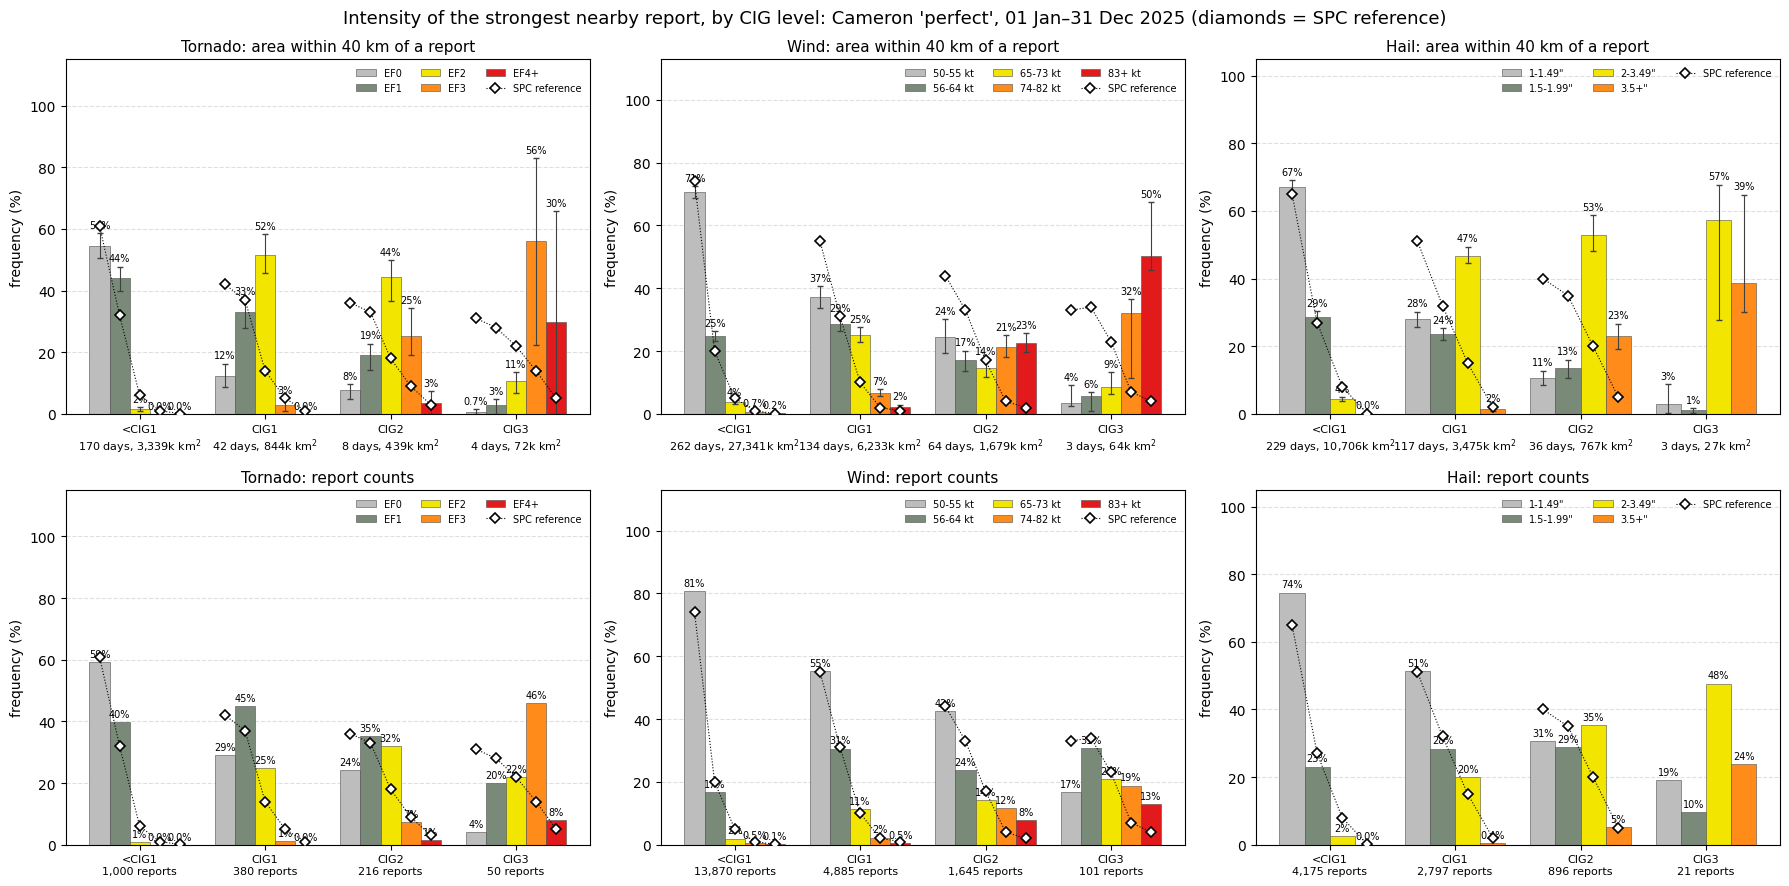

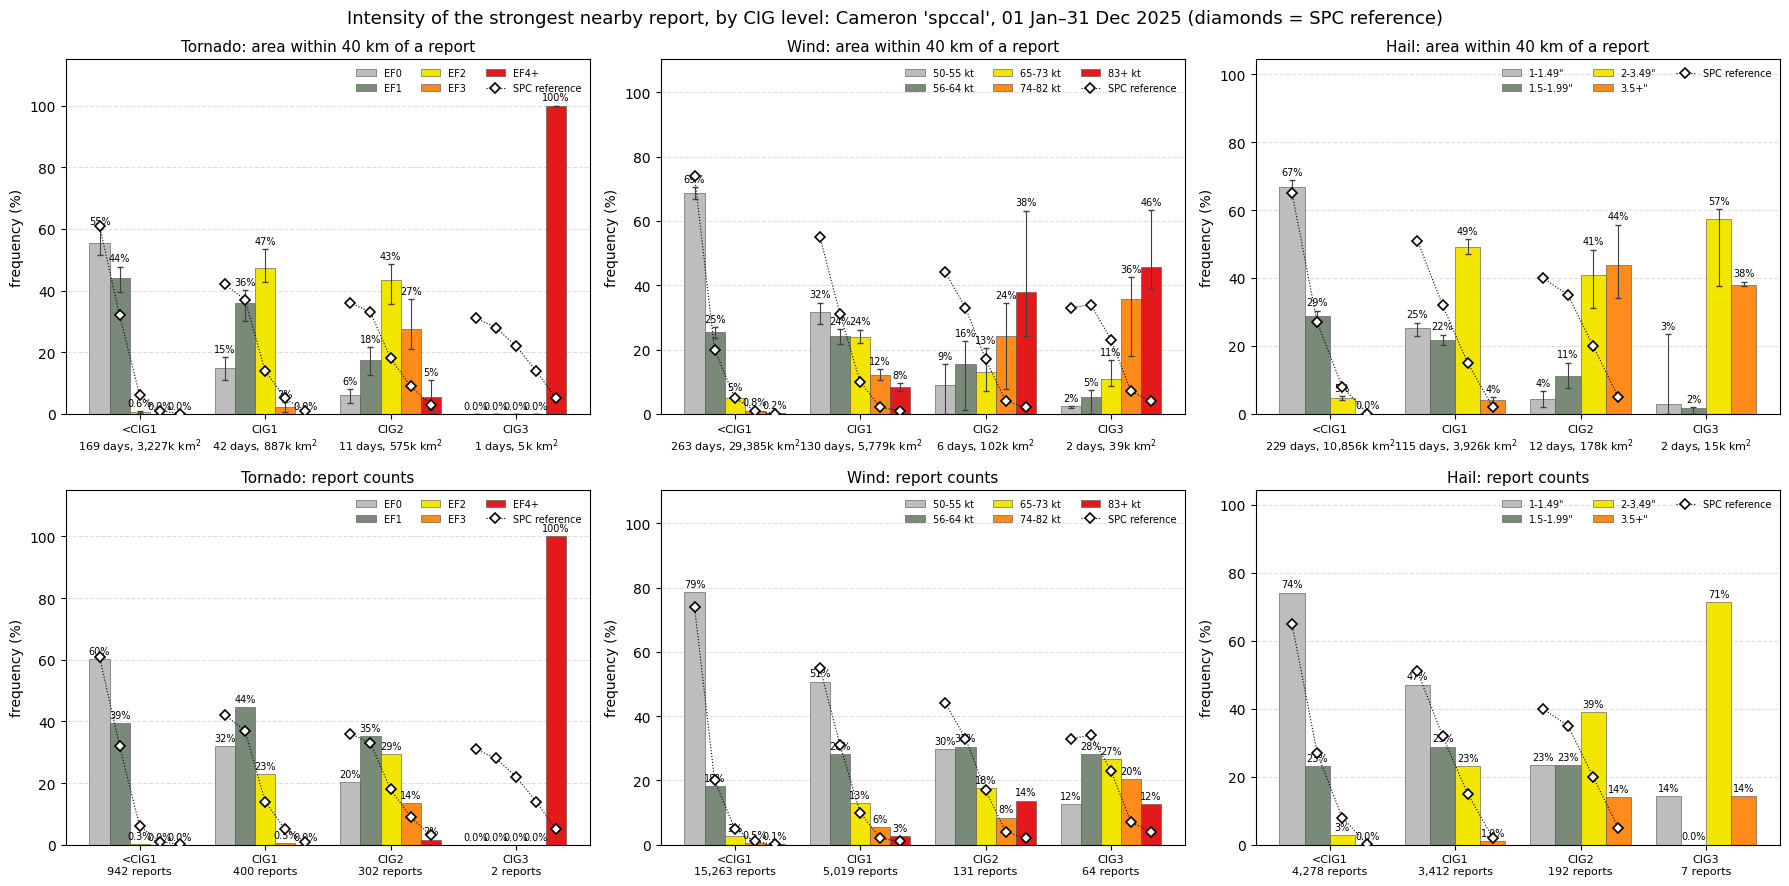

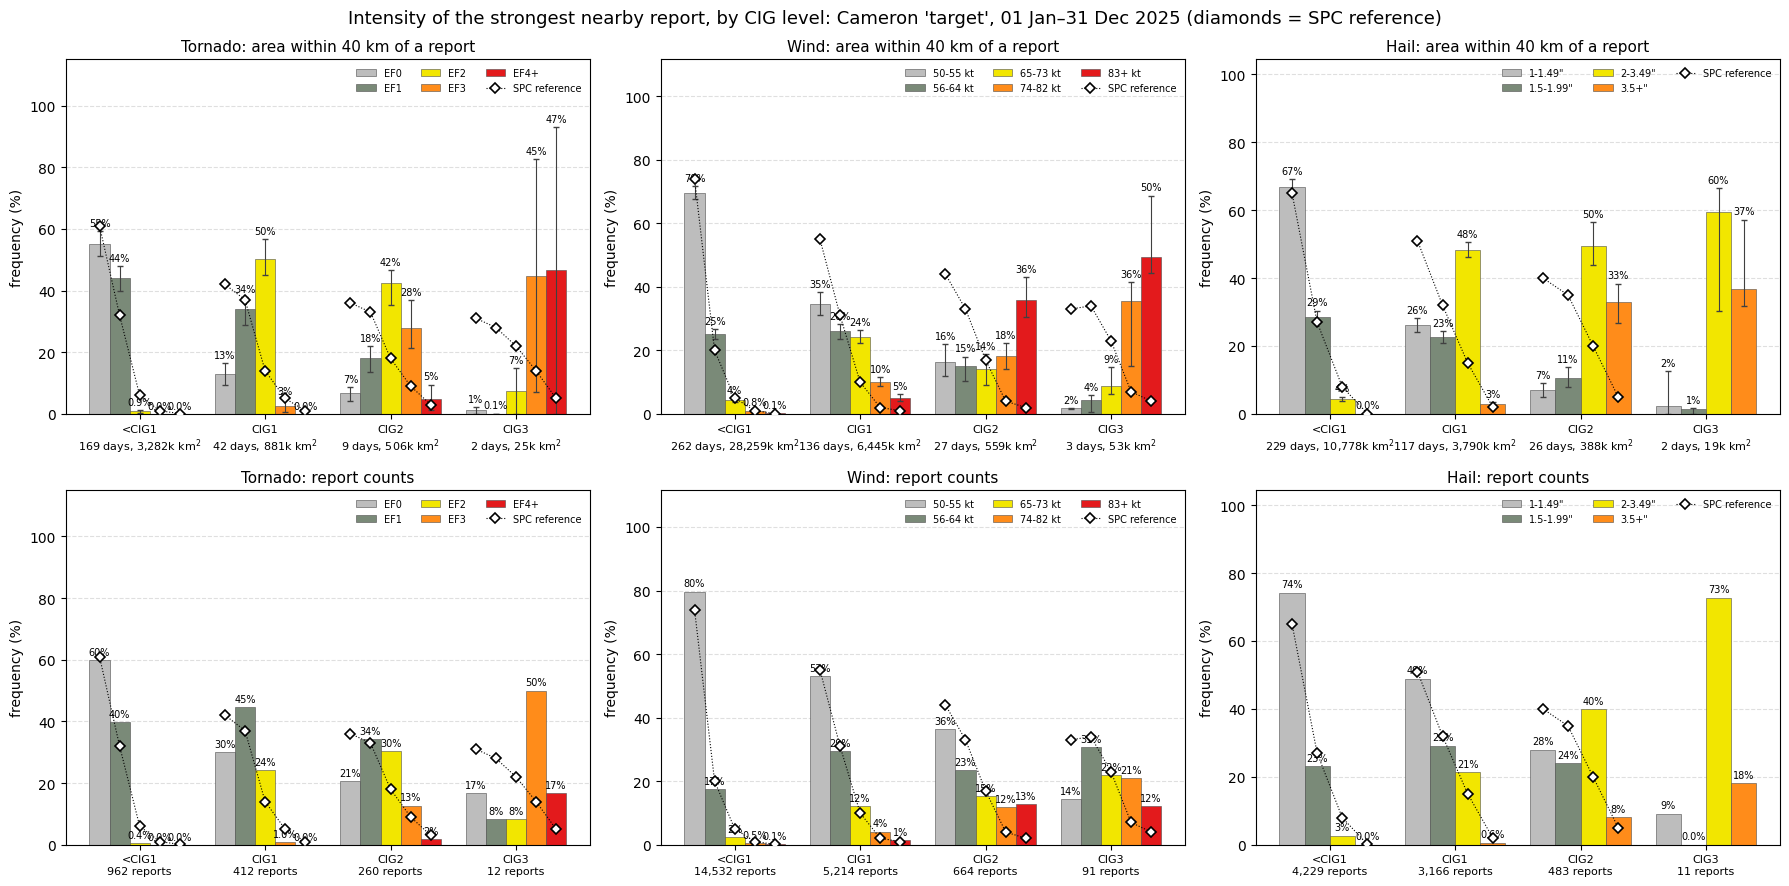

In [13]:
CLASS_NAMES = {'torn': ['EF0', 'EF1', 'EF2', 'EF3', 'EF4+'],
               'wind': ['50-55 kt', '56-64 kt', '65-73 kt', '74-82 kt', '83+ kt'],
               'hail': ['1-1.49"', '1.5-1.99"', '2-3.49"', '3.5+"']}
CLASS_COLORS = ['#bdbdbd', '#7a8a78', '#f2e600', '#ff8c1a', '#e31a1c']
CIG_LEVELS = [0, 1, 2, 3]
CIG_NAMES = {0: '<CIG1', 1: 'CIG1', 2: 'CIG2', 3: 'CIG3'}

def intensity_by_cig(t, haz, n_boot=1000, seed=0):
    # Area-based: share of the "any report within 40 km" area whose strongest nearby report is in each class
    obs = [f'obs_{l}' for l in HAZARDS[haz]['labels']]
    daily = t[t.cig.isin(CIG_LEVELS)].groupby(['cig', 'date'])[obs].sum()
    nxt = daily[obs].shift(-1, axis=1).fillna(0.0)          # the next-higher threshold (0 after the last)
    excl = (daily[obs] - nxt).clip(lower=0)
    excl.columns = CLASS_NAMES[haz]
    rng = np.random.default_rng(seed)
    rows = []
    for c, d in excl.groupby(level='cig'):
        tot = d.sum(axis=1).to_numpy()                       # = obs at the lowest threshold, per day
        x = d.to_numpy()
        share = x.sum(0) / tot.sum() if tot.sum() > 0 else np.full(x.shape[1], np.nan)
        idx = rng.integers(0, len(x), (n_boot, len(x)))
        with np.errstate(invalid='ignore', divide='ignore'):
            boot = x[idx].sum(1) / tot[idx].sum(1)[:, None]
        lo, hi = np.nanpercentile(boot, [5, 95], axis=0)
        for k, name in enumerate(excl.columns):
            rows.append(dict(cig=c, cls=name, share=share[k], lo=lo[k], hi=hi[k],
                             n_days=int((tot > 0).sum()), any_area_km2=tot.sum()))
    return pd.DataFrame(rows)

def intensity_by_cig_counts(rp, haz):
    # Report-count: share of report pieces in each class, by the highest CIG each report touched
    thr = HAZARDS[haz]['thresholds']
    r = rp[rp.cig.isin(CIG_LEVELS)].copy()
    r['cls'] = np.array(CLASS_NAMES[haz])[np.digitize(r.mag, thr) - 1]
    ct = pd.crosstab(r.cig, r.cls).reindex(columns=CLASS_NAMES[haz], fill_value=0)
    out = ct.div(ct.sum(axis=1), axis=0).stack().rename('share').reset_index()
    out['n_reports'] = out.cig.map(ct.sum(axis=1))
    return out

def bar_panel(ax, df, haz, whiskers=True, note_col=None):
    names, ncls = CLASS_NAMES[haz], len(CLASS_NAMES[haz])
    width = 0.8 / ncls
    for k, name in enumerate(names):
        d = df[df.cls == name].set_index('cig').reindex(CIG_LEVELS)
        x = np.arange(len(CIG_LEVELS)) + (k - (ncls - 1) / 2) * width
        ax.bar(x, 100 * d.share, width, color=CLASS_COLORS[k], edgecolor='0.3', lw=0.4, label=name)
        if whiskers and 'lo' in d:
            ax.errorbar(x, 100 * d.share, yerr=[100 * (d.share - d.lo), 100 * (d.hi - d.share)],
                        fmt='none', ecolor='0.25', lw=0.8, capsize=2)
        tops = d.hi if (whiskers and 'hi' in d) else d.share          # put labels above the whiskers
        for xi, v, tp in zip(x, d.share, tops):
            if np.isfinite(v):
                ax.text(xi, 100 * max(v, tp) + 1, f'{100 * v:.0f}%' if v >= 0.01 else f'{100 * v:.1f}%',
                        ha='center', va='bottom', fontsize=7)
    labels = []
    for c in CIG_LEVELS:
        d = df[df.cig == c]
        extra = ''
        if note_col == 'area' and len(d):
            extra = f"\n{d.n_days.iloc[0]} days, {d.any_area_km2.iloc[0] / 1e3:,.0f}k km$^2$"
        elif note_col == 'count' and len(d):
            extra = f"\n{d.n_reports.iloc[0]:,} reports"
        labels.append(CIG_NAMES[c] + extra)
    ax.set_xticks(np.arange(len(CIG_LEVELS)), labels, fontsize=8)
    ax.set_ylabel('frequency (%)'); ax.grid(axis='y', ls='--', alpha=0.4); ax.set_axisbelow(True)
    ax.legend(fontsize=7, ncol=ncls, loc='upper right', frameon=False)


# SPC reference distributions: intensity of reports by CIG level, typed in from the chart labels on
# https://www.spc.noaa.gov/about/outlooks/ (24 Nov 2026). Percent in each class; each row adds to ~100 (rounding).
SPC_REF = {
    'torn': {0: [61, 32, 6, 1, 0.1], 1: [42, 37, 14, 5, 1], 2: [36, 33, 18, 9, 3], 3: [31, 28, 22, 14, 5]},
    'wind': {0: [74, 20, 5, 1, 0.1], 1: [55, 31, 10, 2, 1], 2: [44, 33, 17, 4, 2], 3: [33, 34, 23, 7, 4]},
    'hail': {0: [65, 27, 8, 0.1],    1: [51, 32, 15, 2],    2: [40, 35, 20, 5]},
}

def ref_overlay(ax, haz, ref=SPC_REF):
    # SPC's reference value on top of each bar: a black diamond, joined by a thin line within each CIG level
    from matplotlib.lines import Line2D
    ncls = len(CLASS_NAMES[haz]); width = 0.8 / ncls
    for i, c in enumerate(CIG_LEVELS):
        if c not in ref.get(haz, {}):
            continue
        x = i + (np.arange(ncls) - (ncls - 1) / 2) * width
        ax.plot(x, ref[haz][c], color='k', lw=0.8, ls=':', marker='D', ms=5, mfc='white', mec='k', mew=1.2, zorder=5)
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D([], [], color='k', lw=0.8, ls=':', marker='D', ms=5, mfc='white', mec='k', mew=1.2))
    labels.append('SPC reference')
    ax.legend(handles, labels, fontsize=7, ncol=3, loc='upper right', frameon=False)
    top = max(max(v) for v in ref.get(haz, {}).values())
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, max(hi, top * 1.3 + 14))

def counts_view(rp, m):
    # report pieces with the version's CIG at the report as `cig` (for intensity_by_cig_counts)
    return rp.assign(cig=rp[f'cig_{m}'])

REPS = {haz: pd.read_csv(f'{OUT_DIR}/reports_{haz}.csv', parse_dates=['date']) for haz in HAZARDS}
for m in METHODS:
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    for j, (haz, title) in enumerate([('torn', 'Tornado'), ('wind', 'Wind'), ('hail', 'Hail')]):
        da = intensity_by_cig(view(TILES[haz], m), haz)
        dc = intensity_by_cig_counts(counts_view(REPS[haz], m), haz)
        bar_panel(axes[0, j], da, haz, note_col='area')
        bar_panel(axes[1, j], dc, haz, whiskers=False, note_col='count')
        axes[0, j].set_title(f'{title}: area within 40 km of a report', fontsize=11)
        axes[1, j].set_title(f'{title}: report counts', fontsize=11)
        top = 100 * max(da.hi.max(), dc.share.max())
        for ax in axes[:, j]:
            ax.set_ylim(0, min(115, top * 1.3 + 8))
            ref_overlay(ax, haz)
    fig.suptitle(f"Intensity of the strongest nearby report, by CIG level: Cameron '{m}', "
                 f'{DATES[0]:%d %b}–{DATES[-1]:%d %b %Y} (diamonds = SPC reference)', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/intensity_by_cig_{m}.png', dpi=130)
    plt.show()


## Notes

- **CIG level = integer part** of Cameron's CIG value, following the shading in his plotting code (≥ 1 is CIG1, and so on). If he intends a different rule (rounding, say), change `grid_fields`.
- **Grid boxes.** Each node's value is spread over the 0.36° box centred on it. His `contourf` plots interpolate between nodes instead, so contour areas in his maps will differ slightly from the box areas here.
- **Binned levels** round down, so a 4.9% probability counts in the 2% tornado category (and in the 0 category for wind and hail). The Brier score, MSE and AUC use the exact values.
- **Valid window.** 12Z–12Z is assumed. Section 6 shows which window his areas fit best; if it is a different one, change `WINDOW` and verify against the SPC outlook valid over that window.